In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [3]:
I = cv2.imread("poolTable.png")

# convert to greyscale
G = cv2.cvtColor(I, cv2.COLOR_BGR2GRAY)

# median blur filtering to reduce noise
G = cv2.medianBlur(G, 5)

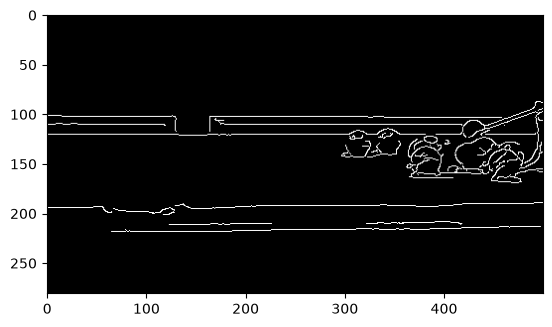

In [4]:
# detect edges using the Canny Edge Detector
E = cv2.Canny(G, 50, 150)

# display the detected edges 
plt.imshow(E, cmap='gray')
plt.show()

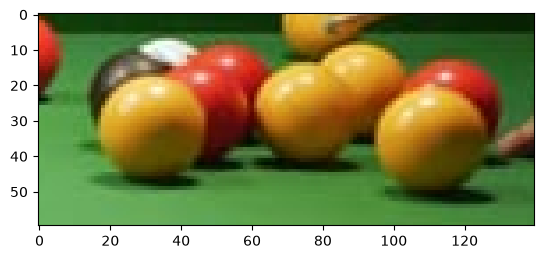

In [5]:
# select the region containing the overlapping pool balls 
ROI = I[115:175, 350:490]

# display the selected region
plt.imshow(cv2.cvtColor(ROI, cv2.COLOR_BGR2RGB))
plt.show()

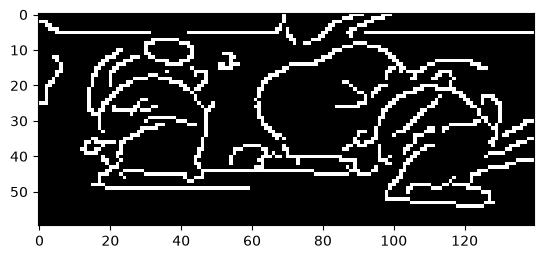

In [6]:
# convert the ROI to greyscale
G_ROI = cv2.cvtColor(ROI, cv2.COLOR_BGR2GRAY)

# apply median filtering
G_ROI = cv2.medianBlur(G_ROI, 5)

# detect the edges in the selected regions 
E_ROI = cv2.Canny(G_ROI, 50, 150)

# display the detected edges
plt.imshow(E_ROI, cmap='gray')
plt.show()

In [7]:
# Week 6: Investigate Contour Detection
# extract contours from the Canny edge image
contours, hierarchy = cv2.findContours(
    E_ROI,
    cv2.RETR_LIST,
    cv2.CHAIN_APPROX_NONE
)


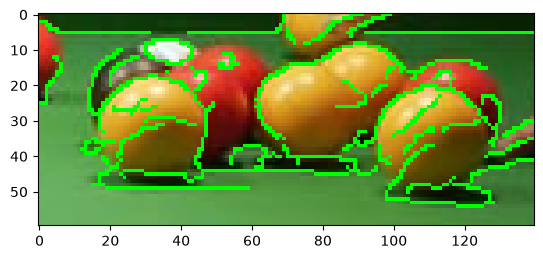

In [8]:
# create a copy of the ROI to display the contours
C = ROI.copy()

# draw all detected contours in green
cv2.drawContours(C, contours, -1, (0, 255, 0), 1)

# display the result
plt.imshow(cv2.cvtColor(C, cv2.COLOR_BGR2RGB))
plt.show()

In [9]:
# count the number of contours detected in the ROI
print("Number of contours detected:", len(contours))

Number of contours detected: 28


In [10]:
# display the number of points in each contour
for i, contour in enumerate(contours):
    print("Contour", i, ":", len(contour), "points")

Contour 0 : 185 points
Contour 1 : 15 points
Contour 2 : 11 points
Contour 3 : 26 points
Contour 4 : 19 points
Contour 5 : 21 points
Contour 6 : 143 points
Contour 7 : 16 points
Contour 8 : 28 points
Contour 9 : 30 points
Contour 10 : 27 points
Contour 11 : 9 points
Contour 12 : 31 points
Contour 13 : 181 points
Contour 14 : 1 points
Contour 15 : 23 points
Contour 16 : 30 points
Contour 17 : 19 points
Contour 18 : 414 points
Contour 19 : 173 points
Contour 20 : 28 points
Contour 21 : 32 points
Contour 22 : 94 points
Contour 23 : 8 points
Contour 24 : 62 points
Contour 25 : 25 points
Contour 26 : 32 points
Contour 27 : 59 points


Contours before filtering: 28
Contours after filtering: 8


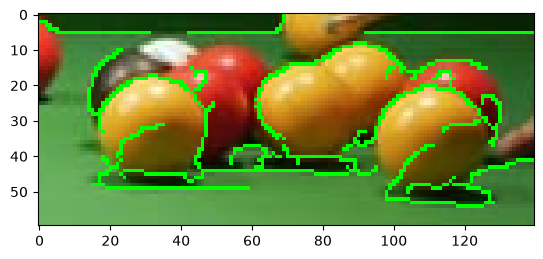

In [11]:
#keep contours containing at least 50 points
filtered_contours = [c for c in contours if len(c) >= 50]

print("Contours before filtering:", len(contours))
print("Contours after filtering:", len(filtered_contours))

# draw the filtered contours on a copy of the ROI
C_filtered = ROI.copy()

cv2.drawContours(C_filtered, filtered_contours, -1, (0, 255, 0), 1)

plt.imshow(cv2.cvtColor(C_filtered, cv2.COLOR_BGR2RGB))
plt.show()


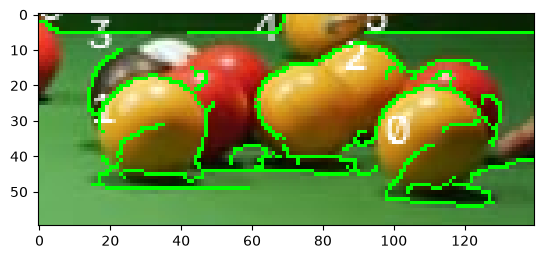

In [ ]:
# display each filtered contour separately with its index
C_numbered = ROI.copy()

for i, contour in enumerate(filtered_contours):

    # draw each contour
    cv2.drawContours(C_numbered, [contour], -1, (0, 255, 0), 1)

    # find the centre of the contour's bounding rectangle
    x, y, w, h = cv2.boundingRect(contour)

    # label the contour with its index
    cv2.putText(
    C_numbered,               # image where the label will be displayed
    str(i),                   # contour index converted to text
    (x, y),                   # position of the label using the bounding rectangle
    cv2.FONT_HERSHEY_SIMPLEX, # font used for the label
    0.4,                      # font size
    (255, 255, 255),          # white text colour (BGR)
    1                         # text thickness
)

plt.imshow(cv2.cvtColor(C_numbered, cv2.COLOR_BGR2RGB))
plt.show()

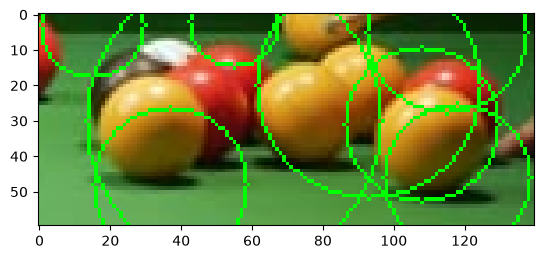

In [21]:
# create a copy of the ROI to display the estimated circles
C_circles = ROI.copy()

# investigate whether the filtered contours can be represented by circles
for contour in filtered_contours:

    # find the smallest circle that contains all points of the contour
    (x, y), radius = cv2.minEnclosingCircle(contour)

    # convert the centre coordinates and radius to integers for drawing
    centre = (int(x), int(y))
    radius = int(radius)

    # draw the estimated circle in green
    cv2.circle(C_circles, centre, radius, (0, 255, 0), 1)

# display the estimated circles
plt.imshow(cv2.cvtColor(C_circles, cv2.COLOR_BGR2RGB))
plt.show()

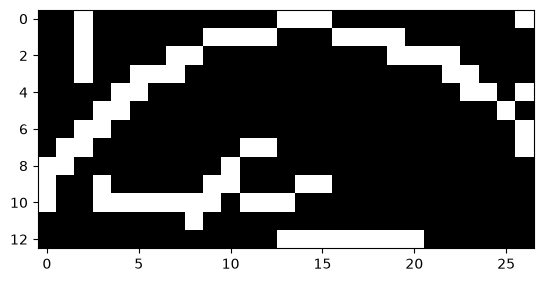

In [22]:
# select a small area containing the visible arc of the left yellow ball
arc = E_ROI[17:30, 18:45]

# display the selected edge region
plt.imshow(arc, cmap='gray')
plt.show()

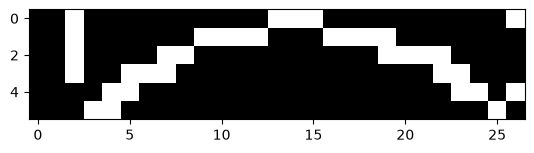

In [23]:
# select the upper curved boundary and exclude most of the lower edges
upper_arc = arc[0:6, :]

# display the selected arc
plt.imshow(upper_arc, cmap='gray')
plt.show()

Number of selected edge points: 28


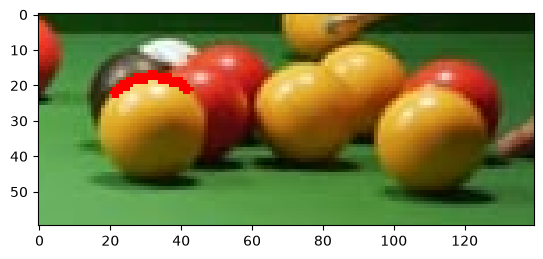

In [24]:
# select the central part of the arc to avoid unwanted edge pixels
selected_arc = upper_arc[:, 3:25]

# find the coordinates of the detected edge pixels
y, x = np.where(selected_arc > 0)

# convert the coordinates back to their positions in the original ROI
x = x + 18 + 3
y = y + 17

# combine the coordinates into points for circle fitting
arc_points = np.column_stack((x, y))

print("Number of selected edge points:", len(arc_points))

# display the selected points on the original ROI
C_points = ROI.copy()

for px, py in arc_points:
    cv2.circle(C_points, (int(px), int(py)), 1, (0, 0, 255), -1)

plt.imshow(cv2.cvtColor(C_points, cv2.COLOR_BGR2RGB))
plt.show()

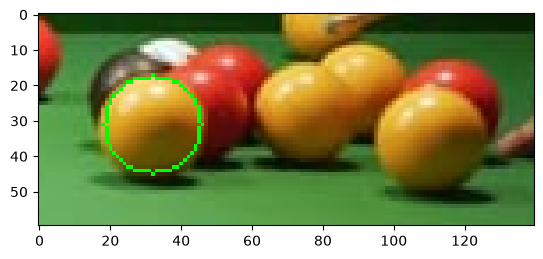

In [26]:
# get the x and y coordinates of the detected arc
x, y = arc_points[:, 0], arc_points[:, 1]

# estimate the circle parameters using least squares
A = np.column_stack((2*x, 2*y, np.ones(len(x))))
cx, cy, c = np.linalg.lstsq(A, x**2 + y**2, rcond=None)[0]

# calculate the estimated radius
r = np.sqrt(c + cx**2 + cy**2)

# draw the estimated circle on the ROI
C_fit = ROI.copy()
cv2.circle(C_fit, (int(cx), int(cy)), int(r), (0, 255, 0), 1)

plt.imshow(cv2.cvtColor(C_fit, cv2.COLOR_BGR2RGB))
plt.show()